# Day 4 lecture: Predictive regression

<p class="lead">
Periods 1 to 3 of Day 4, the first day of Module 2. How a regression becomes a prediction tool a manager can trust: prediction versus explanation, simple and multiple regression, reading a coefficient in dollars with its "holding the others constant" clause, dummy variables and the reference category, training and test sets, R², adjusted R², RMSE and MAE, residual plots, log transformations, multicollinearity and the variance inflation factor, overfitting, extrapolation, confounded coefficients, and why a yes/no outcome needs logistic regression instead.
</p>

Run each code cell with **Shift + Enter**, in order. The examples use **300 synthetic convenience stores** of a fictional chain, "Corner & Co.", generated in the first cells, with each store's annual sales in **thousand US dollars**. Assignment 2 (house prices) and Lab 5 (car fuel economy, tomorrow) use other data; this lecture deliberately uses neither, so that you practise each idea here and apply it yourself there.

- **Route B (Anaconda, offline):** open this notebook from the `DATA300_GAP` folder. It needs only numpy, pandas, matplotlib, statsmodels and scikit-learn, and it downloads nothing.
- **Route A (Try JupyterLab):** upload this notebook and run `%pip install statsmodels scikit-learn` in a first cell.

---

## What you will be able to do

1. Say whether a regression is being used to **predict** or to **explain**, and why the difference changes what you check.
2. Fit **simple** and **multiple** linear regressions and read each coefficient in business units, with its **holding-constant** clause.
3. Use **dummy variables** for a category and say what the **reference category** is.
4. Split data into **training and test** sets and explain why the test score is the honest one.
5. Compute and explain **R²**, **adjusted R²**, **RMSE** and **MAE**, on training and on test data.
6. Read a **residual plot** for a curve (non-linearity) and a funnel (heteroscedasticity), and fix them with a **log** transformation.
7. Detect **multicollinearity** with the **variance inflation factor (VIF)** and decide whether it matters for the model's purpose.
8. Recognise **overfitting** and **extrapolation**, and say why a regression coefficient is not a causal effect.
9. Explain why a yes/no outcome calls for **logistic regression**: probabilities, the sigmoid curve and a threshold.

This lecture fills three periods (P1 to P3). Each part is marked **core** (teach in class) or **extension** (faster students, a later study block, or self-study).

| Part | Topic | Path | Period |
|---|---|---|---|
| 1 | Prediction or explanation? | Core | P1 |
| 2 | Simple regression | Core | P1 |
| 3 | Multiple regression and "holding constant" | Core | P1 |
| 4 | Categories: dummy variables and the reference | Core | P1–P2 |
| 5 | Training and test sets | Core | P2 |
| 6 | R², adjusted R², RMSE and MAE | Core | P2 |
| 7 | Residual plots | Core | P2 |
| 8 | Log transformations | Core (idea), extension (detail) | P2–P3 |
| 9 | Multicollinearity and VIF | Core | P3 |
| 10 | Overfitting | Core (demo), extension (cross-validation) | P3 |
| 11 | Extrapolation | Core | P3 |
| 12 | Correlation, causation and confounded coefficients | Core | P3 |
| 13 | Yes/no outcomes: logistic regression as a concept | Extension | Later |
| 14 | Business case: choosing new store sites | Core (discussion), extension (detail) | P3 |
| 15 | Practice, quiz and summary | Self-study | — |

> **Reading**
>
> Read Chapter 5 of the course reading packet for in-sample fit versus out-of-sample accuracy, the residual plot as a check of constant error size, the variance inflation factor and its threshold of 5, why multicollinearity matters for explaining but much less for predicting, and logistic regression as a contrast (the sigmoid and log loss). Read Gordon, Chapter 8 ("Operational Analytics") for the predictive-maintenance and fraud examples, and Google's *Machine Learning Crash Course* page on logistic regression as a preview. This lecture adds worked examples of every idea, dummy variables, adjusted R², log transformations, overfitting, extrapolation and confounding.

### Setup

The first cell loads the libraries and sets colour-blind-safe colours. The second builds the store data. Because we generate the data ourselves, we know the **true** relationships behind it, so we can check whether each method finds them. With real data you never know the truth, which is exactly why the checks in this lecture matter.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (8, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 11})
# Okabe and Ito colour-blind-safe colours
BLUE, ORANGE, GREEN, PURPLE, SKY, GREY = "#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#9A9A9A"

In [2]:
# 300 synthetic convenience stores of a fictional chain, "Corner & Co."
rng = np.random.default_rng(2026)
n = 300
region = rng.choice(["Downtown", "Suburb", "Rural"], size=n, p=[0.3, 0.45, 0.25])
floor_area = np.clip(rng.normal(3500, 1000, n), 1500, 6500).round(-1)          # square feet
checkouts = np.clip(np.round(floor_area / 700 + rng.normal(0, 0.5, n)), 2, 10).astype(int)
staff = np.round(floor_area / 250 + rng.normal(0, 1.2, n), 1)                   # full-time equivalents
footfall = np.clip(rng.normal(np.select([region == "Downtown", region == "Suburb"], [24, 14], 7), 3.5),
                   2, None).round(1)                                            # thousand passers-by a week
competitor_miles = np.round(np.exp(rng.normal(
    np.select([region == "Downtown", region == "Suburb"], [-1.2, 0.0], 1.2), 0.6)), 2)
parking = (rng.random(n) < np.select([region == "Downtown", region == "Suburb"], [0.2, 0.7], 0.9)).astype(int)
promo = (rng.random(n) < 1 / (1 + np.exp(-(footfall - 15) / 3))).astype(int)   # head office chose busy stores

log_sales = (np.log(1800) + 0.75 * np.log(floor_area / 3500) + 0.030 * (footfall - 14)
             + 0.10 * np.log(competitor_miles + 0.2)
             + np.select([region == "Downtown", region == "Suburb"], [0.05, 0.0], -0.12)
             + 0.06 * parking + 0.02 * promo + rng.normal(0, 0.12, n))
sales = np.round(np.exp(log_sales), 0)                                          # thousand US dollars a year

stores = pd.DataFrame({"region": region, "floor_area": floor_area, "checkouts": checkouts, "staff": staff,
                       "footfall": footfall, "competitor_miles": competitor_miles, "parking": parking,
                       "promo": promo, "sales": sales})
print(stores.shape)
stores.head()

(300, 9)


,region,floor_area,checkouts,staff,footfall,competitor_miles,parking,promo,sales
0,Downtown,5860.0,8,25.8,25.3,0.25,0,1,4140.0
1,Suburb,4480.0,7,15.6,14.2,0.97,1,1,2461.0
2,Suburb,3670.0,5,15.0,15.7,0.55,1,1,1871.0
3,Suburb,3560.0,4,13.8,12.7,1.54,1,1,1930.0
4,Suburb,3950.0,6,17.5,13.9,1.03,1,1,1948.0


| Column | Meaning | Units |
|---|---|---|
| `region` | Where the store is: Downtown, Suburb or Rural | Category |
| `floor_area` | Sales floor area | Square feet |
| `checkouts` | Number of checkout counters | Count |
| `staff` | Staff employed | Full-time equivalents |
| `footfall` | People walking past the door, from city data | Thousand a week |
| `competitor_miles` | Distance to the nearest rival store | Miles |
| `parking` | Customer car park | 1 = yes, 0 = no |
| `promo` | Store ran the chain's loyalty-app promotion last year | 1 = yes, 0 = no |
| `sales` | Annual sales (the **target**) | Thousand US dollars |

The **target** (also called the outcome, response or dependent variable, *y*) is what we want to predict. The other columns are **predictors** (features, explanatory or independent variables, *x*).

---

## Part 1: Prediction or explanation? (core)

A regression is one tool with two very different jobs. Decide which job you are doing **before** you fit anything, because the two jobs need different checks.

| | **Prediction** | **Explanation** |
|---|---|---|
| Question | "What will this store sell?" | "How much does one more checkout add to sales?" |
| What matters | How close the predictions are on **new** cases | Whether each **coefficient** means what it seems to mean |
| Judged by | Test-set error (RMSE, MAE), R² on test data | Sensible signs and sizes, stable coefficients, no confounding, ideally an experiment |
| Correlated predictors | Usually fine | A serious problem (Part 9) |
| A missing cause | Fine if its effect is picked up by other predictors | Biases the coefficients (Part 12) |
| Typical use | Sales forecasts for new sites, pricing a house, fraud scores | Deciding whether to invest in a lever: a promotion, more staff, a car park |

The reading packet describes this as the move from describing the data in hand to predicting what has not happened yet. A predictive model is held to a **stricter** standard: it must work on cases it has never seen.

> **Predict, then run.** Which single column do you expect to have the strongest correlation with `sales`? Which the weakest? Write down your guesses.

In [3]:
numeric = stores.drop(columns="region")
print(numeric.corr()["sales"].drop("sales").sort_values(ascending=False).round(2))

floor_area          0.68
staff               0.65
footfall            0.63
checkouts           0.61
promo               0.44
competitor_miles   -0.18
parking            -0.28
Name: sales, dtype: float64


Floor area, staff, checkouts, footfall and the promotion all go with higher sales; distance to a rival and parking, which are typical of rural stores, are weakly **negative**. Notice that **`promo`** clearly correlates with sales. Does that mean the promotion works? Keep the question in mind until Part 12.

> **Misconception:** "The variable with the biggest correlation is the most important cause." Correlation measures how closely two columns move together. It says nothing about *why*: several of these columns are bigger in big stores, and the promotion was given to busy stores on purpose.

---

## Part 2: Simple regression (core)

A **simple** linear regression uses one predictor:

> **sales = b₀ + b₁ × floor_area + error**

- **b₁, the slope:** how much predicted sales change, on average, when floor area is one unit larger.
- **b₀, the intercept:** predicted sales when floor area is zero. Often it has no business meaning; it just positions the line.
- **error (residual):** actual − predicted, for each store.

**Least squares** picks the line that makes the **sum of squared residuals** as small as possible. Squaring keeps positive and negative misses from cancelling, and punishes big misses more.

> **Predict, then run.** Roughly how many thousand dollars of extra annual sales would you expect for each extra **100 square feet** of floor? Guess a number between 0 and 100.

sales = 428.3 + 0.440 x floor_area     (thousand US dollars)
Each extra 100 sq ft: about $43,967 more annual sales, on average
R-squared: 0.46


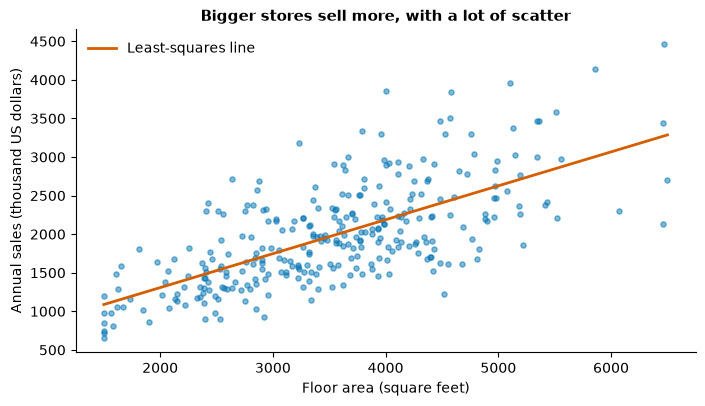

In [4]:
simple = smf.ols("sales ~ floor_area", data=stores).fit()
b0, b1 = simple.params["Intercept"], simple.params["floor_area"]
print(f"sales = {b0:,.1f} + {b1:.3f} x floor_area     (thousand US dollars)")
print(f"Each extra 100 sq ft: about ${b1 * 100 * 1000:,.0f} more annual sales, on average")
print(f"R-squared: {simple.rsquared:.2f}")

fig, ax = plt.subplots()
ax.scatter(stores["floor_area"], stores["sales"], s=14, alpha=0.5, color=BLUE)
xs = np.linspace(stores["floor_area"].min(), stores["floor_area"].max(), 50)
ax.plot(xs, b0 + b1 * xs, color=ORANGE, lw=2, label="Least-squares line")
ax.set_xlabel("Floor area (square feet)")
ax.set_ylabel("Annual sales (thousand US dollars)")
ax.set_title("Bigger stores sell more, with a lot of scatter")
ax.legend(frameon=False)
plt.show()

### Reading the coefficients in business units

Always translate a coefficient into a **sentence with units** and a **sensible step size**. "0.44" is meaningless to a manager; "about $44,000 more sales a year for every extra 100 square feet" is not.

A template:

> "Among stores like these, a store with **[one step more of x]** has, **on average**, about **[b₁ × step, with units]** **[more / less]** **[target]**."

Three things the sentence deliberately says:

1. **"On average"**: individual stores scatter widely around the line.
2. **"Among stores like these"**: the line was fitted to stores from 1,500 to 6,500 square feet (Part 11).
3. **"Has"**, not "would gain if we enlarged it": the data compares different stores; it did not watch a store being enlarged (Part 12).

The intercept here would be the predicted sales of a store with **zero** floor area. No such store exists, so the intercept is just where the line crosses the axis. Do not interpret it.

> **Misconception:** "R² tells us how much of sales floor area *causes*." R² is the share of the variation in sales that the line **accounts for** in this data. About half of the variation is explained by floor area alone; the rest comes from footfall, competition, region and noise.

> **Check your understanding.** A colleague writes: "Increasing floor area by 1 square foot increases sales by 0.44." Name the **two** things wrong with this sentence.

---

## Part 3: Multiple regression and "holding constant" (core)

A **multiple** regression uses several predictors at once:

> **sales = b₀ + b₁ × floor_area + b₂ × footfall + b₃ × competitor_miles + b₄ × parking + error**

Each coefficient now answers a sharper question: **how much do predicted sales differ for one unit more of this predictor, when the other predictors in the model are held at the same values?** That clause, "holding the others constant" (in Latin, *ceteris paribus*), is what makes multiple regression useful, and what makes its coefficients easy to misread.

> **Predict, then run.** Downtown stores have far more footfall than rural ones. When we add footfall to the model, will the floor-area coefficient change a lot or a little? Why?

In [5]:
multi = smf.ols("sales ~ floor_area + footfall + competitor_miles + parking", data=stores).fit()
table = pd.DataFrame({"coefficient": multi.params, "95% CI low": multi.conf_int()[0],
                      "95% CI high": multi.conf_int()[1], "p-value": multi.pvalues})
print(table.round(3))
print(f"\nR-squared: simple model {simple.rsquared:.2f}, multiple model {multi.rsquared:.2f}")

                  coefficient  95% CI low  95% CI high  p-value
Intercept            -492.094    -647.880     -336.307    0.000
floor_area              0.419       0.389        0.449    0.000
footfall               63.380      57.720       69.039    0.000
competitor_miles       21.499       5.468       37.530    0.009
parking                26.671     -44.678       98.021    0.463

R-squared: simple model 0.46, multiple model 0.84


Read each coefficient as a sentence with units and the holding-constant clause:

| Predictor | Sentence (on average, among stores like these) |
|---|---|
| `floor_area` | 100 more square feet goes with about $42,000 more annual sales, **at the same footfall, distance to a rival and parking** |
| `footfall` | 1,000 more passers-by a week goes with about $63,000 more sales, **for stores of the same size, competition and parking** |
| `competitor_miles` | Each extra mile to the nearest rival goes with somewhat higher sales, holding the rest constant |
| `parking` | A car park goes with slightly higher sales, but the confidence interval is wide and includes zero |

The floor-area coefficient barely moved because, in this chain, store size is **not related** to footfall: big and small stores are found in busy and quiet streets alike. When a new predictor is unrelated to the old ones, the old coefficients stay put. When it is related, they shift; Parts 9 and 12 show both.

**The confidence interval** is a range of plausible values for the coefficient given this sample. A **p-value** below 0.05 is the usual sign that a coefficient is distinguishable from zero. For **prediction** these matter less than test-set error; for **explanation** they are a minimum check, not proof.

> **Misconception:** "Holding constant means the model held them constant." Nobody held anything. The model **compares** stores that differ in one predictor but are similar in the others, using the data you gave it. If an important predictor is missing, it is not being held constant at all.

---

## Part 4: Categories: dummy variables and the reference (core)

`region` is text, not a number. A regression handles a category with **dummy variables** (also called indicator or one-hot variables): one 0/1 column per category, **except one**. The category left out is the **reference** (baseline). Each dummy's coefficient is the difference from the reference, holding the other predictors constant.

Why leave one out? With an intercept in the model, the three dummies would always add up to 1, so one is perfectly predictable from the other two. The model cannot separate them: this is the **dummy-variable trap**.

> **Predict, then run.** Downtown stores have the highest **average** sales. Will the Downtown coefficient be positive in a model that also includes footfall and floor area?

In [6]:
print("Average sales by region (thousand US dollars):")
print(stores.groupby("region")["sales"].agg(["count", "mean"]).round(0))

print("\nThe dummies pandas builds (first rows), with 'Downtown' dropped as the reference:")
print(pd.get_dummies(stores["region"], drop_first=True, dtype=int).head(4))

Average sales by region (thousand US dollars):
          count    mean
region                 
Downtown     81  2467.0
Rural        70  1584.0
Suburb      149  1906.0

The dummies pandas builds (first rows), with 'Downtown' dropped as the reference:
   Rural  Suburb
0      0       0
1      0       1
2      0       1
3      0       1


In [7]:
with_default = smf.ols("sales ~ floor_area + footfall + competitor_miles + parking + C(region)",
                       data=stores).fit()
with_suburb = smf.ols("sales ~ floor_area + footfall + competitor_miles + parking"
                      " + C(region, Treatment('Suburb'))", data=stores).fit()

print("Reference = Downtown (alphabetical default):")
print(with_default.params.filter(like="region").round(1))
print("\nReference = Suburb (the largest group):")
print(with_suburb.params.filter(like="region").round(1))

same = np.allclose(with_default.fittedvalues, with_suburb.fittedvalues)
print("\nAre the predictions identical?", same)

Reference = Downtown (alphabetical default):
C(region)[T.Rural]     24.1
C(region)[T.Suburb]    49.3
dtype: float64

Reference = Suburb (the largest group):
C(region, Treatment('Suburb'))[T.Downtown]   -49.3
C(region, Treatment('Suburb'))[T.Rural]      -25.2
dtype: float64

Are the predictions identical? True


Three lessons:

1. **Changing the reference changes the coefficients but not the predictions.** The model is the same; only the comparison point changes. Always say what the reference is: "Rural stores sell about $X thousand less than **suburban** stores of the same size and footfall."
2. **Choose a reference that makes sense to the reader**, usually the largest or the "normal" group. Statsmodels and pandas pick the first in alphabetical order unless you say otherwise.
3. **A raw average and a coefficient answer different questions.** Downtown stores sell the most on average because they have far more footfall. **At the same footfall and size**, the dollar model even puts Downtown slightly **below** a suburb. The log model in Part 8, which fits these data better, gives Downtown a small premium; the data's true recipe (setup cell) gives it 5%. Either way, most of Downtown's raw lead is footfall, not the region itself.

> **Check your understanding.** A model has `day` as a category with seven values. How many dummy columns does it need? If "Monday" is the reference, what does the "Saturday" coefficient mean?

---

## Part 5: Training and test sets (core)

A model fitted to all 300 stores will always fit those 300 stores reasonably well: least squares made it so. That **in-sample** fit says little about the question a predictive model must answer: **how well will it do on a store it has never seen?**

So we hide some data:

1. **Split** the rows at random into a **training set** (commonly 70–80%) and a **test set** (the rest).
2. **Fit** the model on the training set only.
3. **Predict** the test set and measure the errors. The test set plays the role of "new stores".

The test score is the honest one. It is almost always a little worse than the training score; a **big** gap is a warning sign of overfitting (Part 10).

Random splitting suits **cross-sectional** data like these stores, one row per case. On Day 3 you saw that a **time series** must be split in time order instead, because a random split lets the future leak into training.

> **Predict, then run.** Will the model's R² on the test stores be higher or lower than on the training stores? By a lot or a little?

In [8]:
features = ["floor_area", "footfall", "competitor_miles", "parking"]
train, test = train_test_split(stores, test_size=0.2, random_state=1)
print(f"Training stores: {len(train)}, test stores: {len(test)}")

lin = LinearRegression().fit(train[features], train["sales"])
pred_train = lin.predict(train[features])
pred_test = lin.predict(test[features])

print(f"R-squared on training data: {r2_score(train['sales'], pred_train):.3f}")
print(f"R-squared on test data:     {r2_score(test['sales'], pred_test):.3f}")
print("\nCoefficients (fitted on training data only):")
print(pd.Series(lin.coef_, index=features).round(3))

Training stores: 240, test stores: 60
R-squared on training data: 0.843
R-squared on test data:     0.798

Coefficients (fitted on training data only):
floor_area           0.425
footfall            63.079
competitor_miles    15.189
parking             53.081
dtype: float64


Here the gap is small: four sensible predictors and 240 training stores leave little room for memorising noise. On a different random split the numbers move a little; that is normal, and it is one reason Part 10 introduces **cross-validation**.

Rules for using a test set well:

1. **Split first**, before exploring or choosing features, so that nothing about the test rows shapes the model.
2. **Fix `random_state`** so that you and your reader get the same split.
3. **Use the test set once**, at the end. If you try twenty models and keep the one with the best test score, the test set has quietly become part of training.
4. After choosing the model, it is fine to **refit on all the data** for the final predictions.

> **Misconception:** "The test score is the model's accuracy, so it will be exactly this good in future." It is an **estimate** from one sample of stores. New stores may differ from old ones (new regions, a new competitor), and then the error will be larger.

---

## Part 6: R², adjusted R², RMSE and MAE (core)

For each store, **residual = actual − predicted**. Four summaries of the residuals:

| Measure | Formula | Units | How to say it |
|---|---|---|---|
| **R²** | 1 − (sum of squared residuals) ÷ (sum of squared deviations from the mean) | None (≤ 1) | "The model accounts for about 84% of the variation in sales between stores" |
| **Adjusted R²** | 1 − (1 − R²) × (n − 1) ÷ (n − k − 1), with *k* predictors | None | Like R², but with a penalty for each predictor: it rises only if a new predictor improves the fit by more than chance would |
| **RMSE** | √(mean of squared residuals) | Same as the target | "Predictions are typically off by about $X thousand; big misses weigh more" |
| **MAE** | mean of \|residuals\| | Same as the target | "On average, predictions miss by about $X thousand" |

Points that trip people up:

- **R² is not "accuracy" or "percent correct".** An R² of 0.84 does not mean 84% of predictions are right. It compares the model's squared errors with those of the simplest possible prediction: the mean.
- **R² on test data can be negative**: that happens when the model does worse than just predicting the training mean.
- **RMSE ≥ MAE always.** The bigger the gap, the more the errors include a few large misses.
- **Judge RMSE and MAE against the scale**: a $150 thousand error is small for a $4 million store and huge for a $1 million one.

> **Predict, then run.** Compute each measure by hand from the residuals, then check it against scikit-learn. Before running, guess: is the test RMSE closer to $50 thousand, $250 thousand or $500 thousand?

In [9]:
resid = test["sales"].values - pred_test
sse = np.sum(resid ** 2)
sst = np.sum((test["sales"].values - test["sales"].mean()) ** 2)
r2_hand = 1 - sse / sst
rmse_hand = np.sqrt(np.mean(resid ** 2))
mae_hand = np.mean(np.abs(resid))
n_test, k = len(test), len(features)
adj_r2 = 1 - (1 - r2_hand) * (n_test - 1) / (n_test - k - 1)

print(f"R-squared   by hand {r2_hand:.3f}   sklearn {r2_score(test['sales'], pred_test):.3f}")
print(f"Adjusted R-squared  {adj_r2:.3f}")
print(f"RMSE        by hand {rmse_hand:6.1f}   sklearn {np.sqrt(mean_squared_error(test['sales'], pred_test)):6.1f}  thousand US dollars")
print(f"MAE         by hand {mae_hand:6.1f}   sklearn {mean_absolute_error(test['sales'], pred_test):6.1f}  thousand US dollars")

baseline = np.full(n_test, train["sales"].mean())     # predict the training average for every store
print(f"\nBaseline (always predict the training mean): RMSE {np.sqrt(np.mean((test['sales'] - baseline) ** 2)):6.1f}")
print(f"Typical test store sells about {test['sales'].median():,.0f} thousand US dollars a year")

R-squared   by hand 0.798   sklearn 0.798
Adjusted R-squared  0.783
RMSE        by hand  262.4   sklearn  262.4  thousand US dollars
MAE         by hand  203.0   sklearn  203.0  thousand US dollars

Baseline (always predict the training mean): RMSE  593.0
Typical test store sells about 1,962 thousand US dollars a year


The baseline matters: an RMSE means little until you compare it with **what you would do without a model**. Here the model cuts the typical error by well over half compared with "every store sells the average".

### Why adjusted R² exists

Plain R² on the training data **never falls** when you add a predictor, even one made of pure noise: least squares can always use it a little. Adjusted R² charges a penalty for each extra predictor.

> **Predict, then run.** We add 30 columns of random numbers, which have nothing to do with sales, to the training data. What happens to training R², adjusted R², and test RMSE?

In [10]:
noise_rng = np.random.default_rng(5)
noise_cols = [f"noise_{j}" for j in range(30)]
train_noisy = train.copy()
test_noisy = test.copy()
for col in noise_cols:
    train_noisy[col] = noise_rng.normal(size=len(train))
    test_noisy[col] = noise_rng.normal(size=len(test))

rows = []
for label, cols in [("4 real predictors", features), ("4 real + 30 noise", features + noise_cols)]:
    m = smf.ols("sales ~ " + " + ".join(cols), data=train_noisy).fit()
    p = m.predict(test_noisy)
    rows.append({"model": label, "train R2": m.rsquared, "train adj R2": m.rsquared_adj,
                 "test RMSE": np.sqrt(mean_squared_error(test_noisy["sales"], p))})
print(pd.DataFrame(rows).round(3).to_string(index=False))

            model  train R2  train adj R2  test RMSE
4 real predictors     0.843         0.841    262.377
4 real + 30 noise     0.867         0.845    293.676


Training R² went **up** noticeably, as it always does. Adjusted R² barely moved: its penalty roughly cancels the gain that pure noise gives, so it does not reward the junk (with useless predictors it is as likely to fall as to rise slightly). The test RMSE got **worse**: the noise columns fitted quirks of the training stores that do not repeat. This is overfitting in miniature (Part 10).

> **Check your understanding.** Model A has training R² 0.90 and test R² 0.60. Model B has training R² 0.82 and test R² 0.80. Which would you deploy for predicting new stores, and why?

---

## Part 7: Residual plots (core)

R² and RMSE are averages; they can hide **where** a model goes wrong. A **residual plot** (residuals on the vertical axis, predicted values on the horizontal) shows it. What you want is a **shapeless band centred on zero**, the same width all the way across.

Two patterns to recognise:

| Pattern | Name | What it means | Typical fix |
|---|---|---|---|
| A **curve** (a smile or a frown) | **Non-linearity** | A straight line is the wrong shape for the relationship | Transform a variable (Part 8), add a squared term, or use a different model |
| A **funnel** (spread grows or shrinks) | **Heteroscedasticity** (non-constant variance) | Errors are bigger for some cases than others; the RMSE overstates accuracy for some and understates it for others | Log the target (Part 8); report errors in percent; use robust standard errors |

The reading packet stresses that two models can share the same R² while one has evenly spread errors and the other has errors that grow for the largest cases. Only the residual plot shows the difference.

> **Predict, then run.** Three simulated data sets follow. Before you look at the bottom row, sketch what each residual plot will look like.

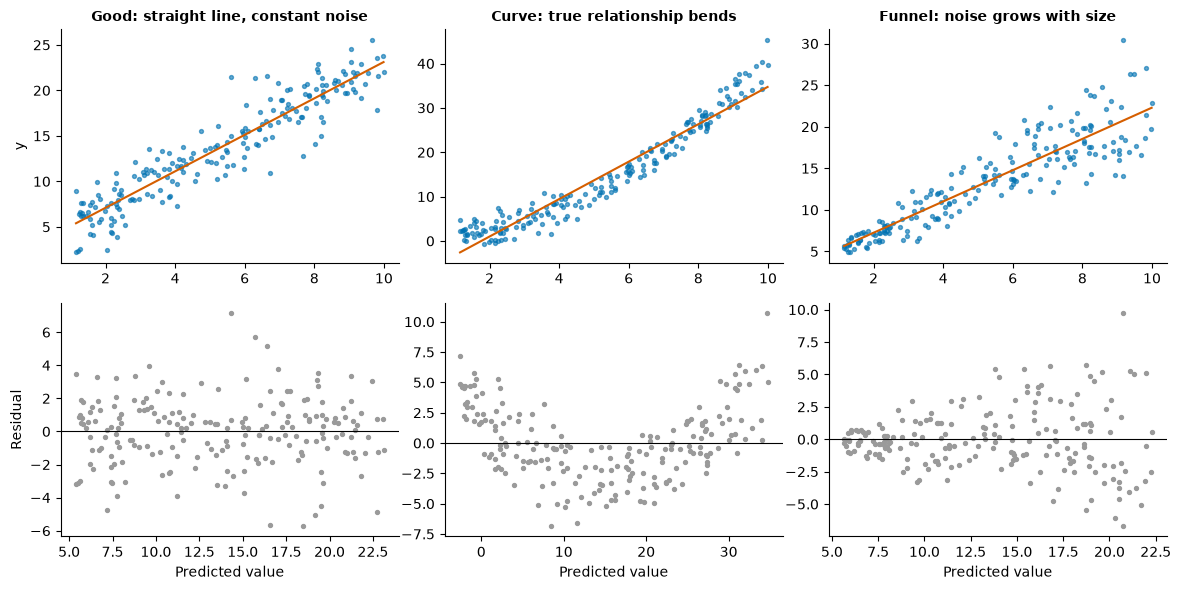

In [11]:
sim = np.random.default_rng(11)
x = np.sort(sim.uniform(1, 10, 200))
cases = {
    "Good: straight line, constant noise": 3 + 2 * x + sim.normal(0, 2, 200),
    "Curve: true relationship bends": 1 + 0.4 * x ** 2 + sim.normal(0, 2, 200),
    "Funnel: noise grows with size": 3 + 2 * x + sim.normal(0, 0.4 * x, 200),
}
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for col, (title, y) in enumerate(cases.items()):
    slope, intercept = np.polyfit(x, y, 1)
    fitted = intercept + slope * x
    axes[0, col].scatter(x, y, s=8, color=BLUE, alpha=0.6)
    axes[0, col].plot(x, fitted, color=ORANGE)
    axes[0, col].set_title(title, fontsize=10)
    axes[1, col].scatter(fitted, y - fitted, s=8, color=GREY)
    axes[1, col].axhline(0, color="black", lw=0.8)
    axes[1, col].set_xlabel("Predicted value")
axes[0, 0].set_ylabel("y")
axes[1, 0].set_ylabel("Residual")
plt.tight_layout()
plt.show()

Now the store model. We draw the residual plot for the **training** stores (more points make the pattern easier to see), with a smooth trend line through the residuals to help the eye.

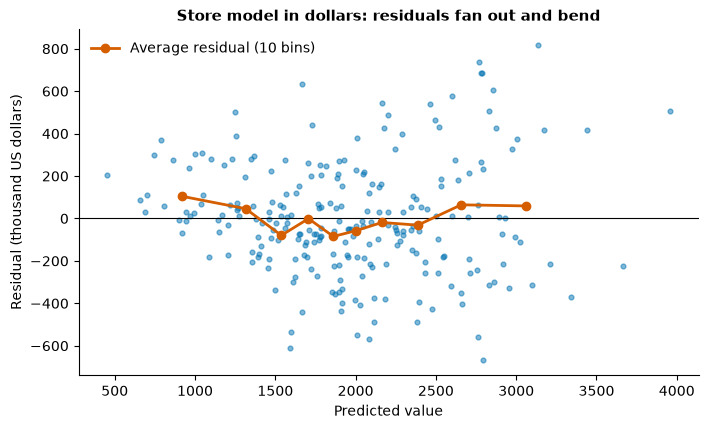

In [12]:
def residual_plot(fitted, residuals, title, ax=None, ylabel="Residual (thousand US dollars)"):
    """Residuals against predicted values, with a binned average to show any curve."""
    ax = ax or plt.gca()
    ax.scatter(fitted, residuals, s=12, alpha=0.5, color=BLUE)
    ax.axhline(0, color="black", lw=0.8)
    bins = pd.qcut(fitted, 10)
    trend = pd.DataFrame({"f": fitted, "r": residuals}).groupby(bins, observed=True).mean()
    ax.plot(trend["f"], trend["r"], color=ORANGE, lw=2, marker="o", label="Average residual (10 bins)")
    ax.set_xlabel("Predicted value")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(frameon=False, loc="upper left")

level_model = smf.ols("sales ~ floor_area + footfall + competitor_miles + parking", data=train).fit()
fig, ax = plt.subplots(figsize=(8, 4.5))
residual_plot(level_model.fittedvalues.values, level_model.resid.values,
              "Store model in dollars: residuals fan out and bend", ax=ax)
plt.show()

Two problems are visible:

1. **A funnel.** The residuals spread out as predicted sales grow: the model misses big stores by far more dollars than small ones. That is heteroscedasticity, and it makes a single RMSE misleading: it is too pessimistic for small stores and too optimistic for big ones.
2. **A slight curve.** The average residual is positive at both ends and negative in the middle: the effects multiply rather than add, so a straight line in dollars is the wrong shape.

Neither problem stops the model from predicting reasonably on average, but both say we can do better, and that any statement like "accurate to within $X" needs care.

Two more checks are worth knowing (extension):

- **Residuals against each predictor**: a curve against one predictor says *that* predictor needs transforming.
- **Influential points**: one extreme store can tilt a line. Look at the largest residuals and ask whether they are errors in the data, or real but unusual cases.

> **Misconception:** "The residuals should be normally distributed, so the data must be normal." The assumptions are about the **errors**, not the raw columns. Skewed predictors are fine. And for prediction, a funnel or a curve matters more than exact normality.

---

## Part 8: Log transformations (core idea, extension detail)

Money, sizes and counts often behave **multiplicatively**: a 10% bigger store sells roughly 7% more, whether it is a small store or a big one. In dollars that is a curve with errors that grow with size, exactly the two patterns in Part 7. Taking the **natural log** turns multiplying into adding, which a linear regression can model.

How to read the coefficients after logging:

| Model | Coefficient *b* on *x* means… |
|---|---|
| log(y) = … + *b* × x | One more unit of x goes with about **100 × b %** more y (exact: (e^b − 1) × 100%) |
| log(y) = … + *b* × log(x) | 1% more x goes with about **b %** more y (an **elasticity**) |
| y = … + *b* × log(x) | 1% more x goes with about **b ÷ 100** more units of y |

Logs need positive values. For a column that can be zero, use `np.log1p` (log of 1 + x) or reconsider.

> **Predict, then run.** After logging sales and floor area, will the residual plot still fan out?

Intercept                                     0.870
C(region, Treatment('Suburb'))[T.Downtown]    0.032
C(region, Treatment('Suburb'))[T.Rural]      -0.113
np.log(floor_area)                            0.762
footfall                                      0.032
np.log(competitor_miles)                      0.071
parking                                       0.037
dtype: float64


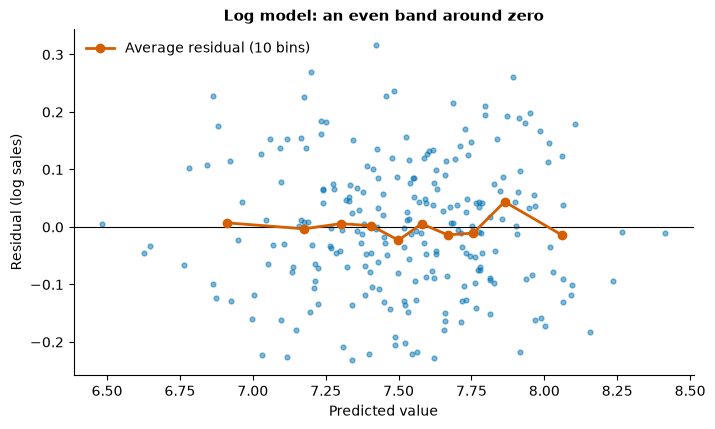

In [13]:
log_formula = ("np.log(sales) ~ np.log(floor_area) + footfall + np.log(competitor_miles) + parking"
               " + C(region, Treatment('Suburb'))")
log_model = smf.ols(log_formula, data=train).fit()
print(log_model.params.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
residual_plot(log_model.fittedvalues.values, log_model.resid.values,
              "Log model: an even band around zero", ax=ax, ylabel="Residual (log sales)")
plt.show()

The band is now even and flat. Reading two coefficients:

- `np.log(floor_area)` ≈ 0.76: a store with **1% more** floor area sells about **0.76% more**, holding the rest constant. A 10% bigger store sells roughly 7.5% more, not 10% more.
- `footfall` ≈ 0.03: each extra thousand passers-by a week goes with about **3% more** sales.

These are close to the true values in the setup cell (0.75 and 0.030), which we only know because the data is synthetic.

### Comparing the two models fairly (extension)

To compare with the dollar model, **convert predictions back** to dollars with `np.exp` and compute the errors in dollars on the **same test stores**. (Strictly, `exp` of a predicted log gives something closer to the median than the mean; with small residuals like these the difference is about 1%, so we ignore it.)

In [14]:
level_pred = level_model.predict(test)
log_pred = np.exp(log_model.predict(test))

for label, p in [("Dollar model (4 predictors)", level_pred), ("Log model (with region)", log_pred)]:
    print(f"{label:28s} test RMSE {np.sqrt(mean_squared_error(test['sales'], p)):6.1f}   "
          f"MAE {mean_absolute_error(test['sales'], p):6.1f}   R2 {r2_score(test['sales'], p):.3f}")

pct_err = np.abs(test["sales"] - log_pred) / test["sales"] * 100
print(f"\nLog model: median absolute error is {pct_err.median():.1f}% of a store's sales")

Dollar model (4 predictors)  test RMSE  262.4   MAE  203.0   R2 0.798
Log model (with region)      test RMSE  235.0   MAE  189.5   R2 0.838

Log model: median absolute error is 8.5% of a store's sales


The log model predicts the test stores better, and it gives a more honest way to describe accuracy: **in percent**. "Half of the predictions are within about 8 or 9% of actual sales" is true for small and large stores alike, whereas a single dollar RMSE is not.

> **Misconception:** "Transforming the data is cheating." Choosing the right **shape** for a relationship is part of modelling. What would be cheating is choosing it by repeatedly checking the test set; choose it from the training residuals, as here, then test once.

---

## Part 9: Multicollinearity and VIF (core)

**Multicollinearity** means two or more predictors are strongly correlated with **each other**. It is normal in business data: bigger stores have more floor area, more checkouts **and** more staff, for structural reasons.

The problem is for **explanation**. If floor area, checkouts and staff always rise together, the data has almost no stores where one is high and the others are low, so the model cannot tell which one deserves the credit. The coefficients become **unstable**: small changes in the data swing them, sometimes flipping their signs, while the predictions barely change.

The **variance inflation factor** for predictor *j* is

> **VIF_j = 1 ÷ (1 − R²_j)**,

where R²_j comes from regressing predictor *j* on **all the other predictors**. A VIF of 1 means no overlap. A VIF of 5 means 80% of that predictor's variation is already explained by the others, and its coefficient's variance is five times what it would be without the overlap. The usual flag is **VIF > 5** (some use 10).

> **Predict, then run.** We add `checkouts` and `staff` to the dollar model. Which predictors will have a VIF above 5?

In [15]:
size_cols = ["floor_area", "checkouts", "staff", "footfall", "competitor_miles", "parking"]
print("Correlations among the size measures:")
print(train[["floor_area", "checkouts", "staff"]].corr().round(2))

def vif_table(data, cols):
    """VIF by the definition: regress each predictor on all the others."""
    out = {}
    for c in cols:
        others = [o for o in cols if o != c]
        r2_j = smf.ols(f"{c} ~ " + " + ".join(others), data=data).fit().rsquared
        out[c] = 1 / (1 - r2_j)
    return pd.Series(out, name="VIF").round(1)

print("\nVIF with all six predictors:")
print(vif_table(train, size_cols))

Correlations among the size measures:
            floor_area  checkouts  staff
floor_area        1.00       0.94   0.97
checkouts         0.94       1.00   0.91
staff             0.97       0.91   1.00

VIF with all six predictors:
floor_area          23.9
checkouts            8.4
staff               16.3
footfall             1.6
competitor_miles     1.4
parking              1.3
Name: VIF, dtype: float64


Floor area, checkouts and staff all have VIFs well above 5: each is largely predictable from the other two. Footfall, distance and parking are near 1.

`statsmodels` has a ready-made function, `variance_inflation_factor` in `statsmodels.stats.outliers_influence`. It needs a constant column in the design matrix and gives the same numbers as the definition above; computing VIF by hand once makes clear what it measures.

### What multicollinearity does, and does not, do

> **Predict, then run.** We refit the six-predictor model on five **bootstrap** samples (training stores drawn at random with replacement). Will the floor-area, checkouts and staff coefficients stay similar? Will the test RMSE?

In [16]:
boot = np.random.default_rng(3)
rows = []
for b in range(5):
    sample = train.iloc[boot.integers(0, len(train), len(train))]
    m = smf.ols("sales ~ " + " + ".join(size_cols), data=sample).fit()
    rows.append({"sample": b + 1,
                 "floor_area (per 100 sq ft)": m.params["floor_area"] * 100,
                 "checkouts (per counter)": m.params["checkouts"],
                 "staff (per FTE)": m.params["staff"],
                 "test RMSE": np.sqrt(mean_squared_error(test["sales"], m.predict(test)))})
print(pd.DataFrame(rows).round(1).to_string(index=False))

 sample  floor_area (per 100 sq ft)  checkouts (per counter)  staff (per FTE)  test RMSE
      1                        34.1                     -9.1             23.2      257.7
      2                        49.4                    -33.7             -6.0      260.9
      3                        49.9                     -8.9            -21.6      257.2
      4                        52.4                    -39.8             -5.8      268.6
      5                        49.9                    -50.5              4.5      262.9


The three size coefficients jump around from sample to sample, and some change sign, while the test RMSE hardly moves. That is the reading packet's point in action:

- **For prediction**, multicollinearity is usually tolerable: the model still combines the size measures into a good overall prediction, **as long as new stores have the same pattern** (bigger stores with more staff). If a new store breaks the pattern (huge floor, two checkouts), predictions become unreliable.
- **For explanation**, a high VIF disqualifies that coefficient. "Each extra checkout adds $X thousand" cannot be read from this model.

What to do about it, depending on the purpose:

| Option | When |
|---|---|
| Leave it | The purpose is prediction and new cases follow the old pattern |
| Drop one of the overlapping predictors | You need interpretable coefficients and one measure carries the idea (floor area) |
| Combine them into one index (e.g. "store size") | The measures are different views of one underlying property |
| Collect data that breaks the pattern, or run an experiment | You genuinely need the separate effect (e.g. of adding a checkout) |
| Regularisation (ridge regression) | Many correlated predictors; mentioned again in the text-features lecture |

> **Misconception:** "A high VIF means the model is wrong and must be fixed." It means **individual coefficients** are unreliable. Whether that matters depends on what the model is for, which is why Part 1 asked the question first.

---

## Part 10: Overfitting (core demo, extension cross-validation)

A model **overfits** when it learns the noise in the training data as if it were pattern. It fits the training data very well and new data badly. Flexible models (many predictors, high-degree curves) on small samples overfit most.

> **Predict, then run.** Using only **25 training stores**, we fit polynomials of floor area of degree 1 (a line) up to 9 (a very wiggly curve), and test each on 100 other stores. Which degree will have the lowest **training** error? The lowest **test** error?

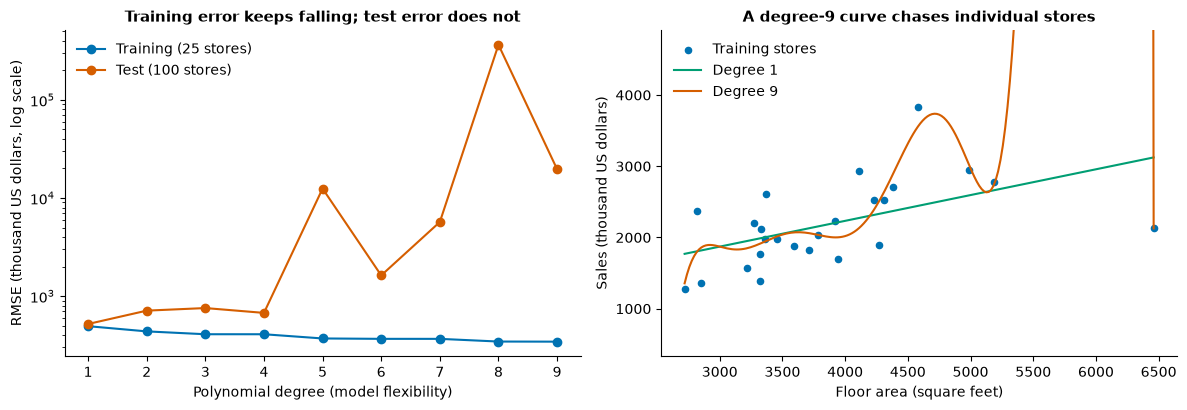

 degree  train RMSE  test RMSE
      1       493.0      518.9
      2       436.3      710.0
      3       408.0      754.4
      4       407.9      673.5
      5       369.4    12479.7
      6       366.1     1624.5
      7       366.0     5694.2
      8       343.6   365411.0
      9       342.7    19663.0


In [17]:
small = stores.sample(125, random_state=4)
small_train, small_test = small.iloc[:25], small.iloc[25:]
centre, scale = small_train["floor_area"].mean(), small_train["floor_area"].std()
z_train = (small_train["floor_area"] - centre) / scale       # standardise so high powers stay manageable
z_test = (small_test["floor_area"] - centre) / scale

rows = []
for degree in range(1, 10):
    coefs = np.polyfit(z_train, small_train["sales"], degree)
    rows.append({"degree": degree,
                 "train RMSE": np.sqrt(np.mean((small_train["sales"] - np.polyval(coefs, z_train)) ** 2)),
                 "test RMSE": np.sqrt(np.mean((small_test["sales"] - np.polyval(coefs, z_test)) ** 2))})
curve = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(curve["degree"], curve["train RMSE"], marker="o", color=BLUE, label="Training (25 stores)")
axes[0].plot(curve["degree"], curve["test RMSE"], marker="o", color=ORANGE, label="Test (100 stores)")
axes[0].set_xlabel("Polynomial degree (model flexibility)")
axes[0].set_ylabel("RMSE (thousand US dollars, log scale)")
axes[0].set_title("Training error keeps falling; test error does not")
axes[0].set_yscale("log")
axes[0].legend(frameon=False)

grid = np.linspace(z_train.min(), z_train.max(), 200)
axes[1].scatter(small_train["floor_area"], small_train["sales"], color=BLUE, s=20, label="Training stores")
for degree, colour in [(1, GREEN), (9, ORANGE)]:
    coefs = np.polyfit(z_train, small_train["sales"], degree)
    axes[1].plot(grid * scale + centre, np.polyval(coefs, grid), color=colour, label=f"Degree {degree}")
axes[1].set_ylim(stores["sales"].min() * 0.5, stores["sales"].max() * 1.1)
axes[1].set_xlabel("Floor area (square feet)")
axes[1].set_ylabel("Sales (thousand US dollars)")
axes[1].set_title("A degree-9 curve chases individual stores")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()
print(curve.round(1).to_string(index=False))

Training error falls with every extra degree: more flexibility always fits the sample better. Test error is lowest for the straight line and then rises, explosively for the wiggliest curves (the left chart needs a log scale to show them at all). The degree-9 curve passes close to the training stores and swings wildly between and beyond them.

Defences against overfitting:

1. **Judge on test data**, never on training fit alone.
2. **Prefer simpler models** unless a more complex one clearly wins on test data.
3. **More data**: the same degree-9 curve overfits far less with 2,000 stores than with 25.
4. **Regularisation** (ridge, lasso) shrinks coefficients towards zero; the reading packet's logistic regression reading mentions it as a defence.
5. **Cross-validation** (below) when choosing between models.

### Cross-validation (extension)

One random split gives one noisy estimate. **k-fold cross-validation** splits the training data into *k* parts, fits on *k* − 1 of them and tests on the remaining part, *k* times, then averages. Use it to **choose** a model; keep the real test set for the final check.

In [18]:
folds = KFold(n_splits=5, shuffle=True, random_state=0)
X_log = pd.DataFrame({"log_area": np.log(train["floor_area"]), "footfall": train["footfall"],
                      "log_comp": np.log(train["competitor_miles"]), "parking": train["parking"]})
for label, X in [("Floor area only", X_log[["log_area"]]), ("Four predictors", X_log)]:
    scores = cross_val_score(LinearRegression(), X, np.log(train["sales"]), cv=folds, scoring="r2")
    print(f"{label:16s} R2 in each fold: {np.round(scores, 2)}   mean {scores.mean():.2f}")

Floor area only  R2 in each fold: [0.54 0.43 0.41 0.6  0.45]   mean 0.48
Four predictors  R2 in each fold: [0.92 0.86 0.86 0.88 0.82]   mean 0.87


---

## Part 11: Extrapolation (core)

A regression learns the relationship **within the range of the data**. Using it far outside that range, **extrapolation**, assumes the relationship carries on unchanged, which the data cannot confirm.

Corner & Co. is considering a **15,000 square foot** "superstore". The largest store in the data is 6,500 square feet.

> **Predict, then run.** Will the dollar model and the log model give similar predictions for the superstore? (They agreed closely on the test stores.)

Training range of floor area: 1,500 to 6,500 sq ft
Dollar model prediction: 6,811 thousand US dollars
Log model prediction:    5,897 thousand US dollars


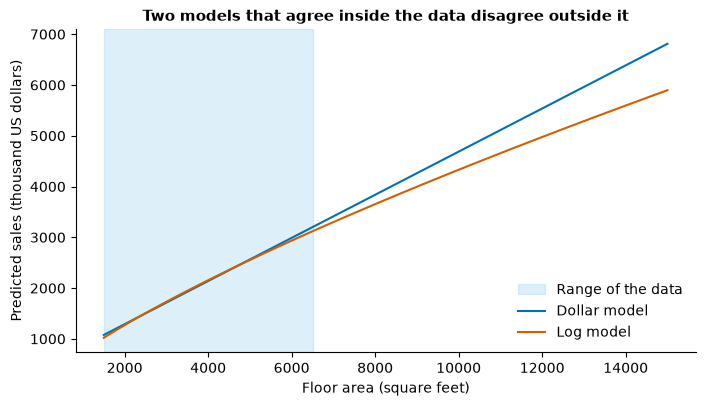

In [19]:
superstore = pd.DataFrame({"floor_area": [15000], "footfall": [14.0], "competitor_miles": [1.0],
                           "parking": [1], "region": ["Suburb"]})
dollar_pred = level_model.predict(superstore).iloc[0]
log_point = np.exp(log_model.predict(superstore).iloc[0])
print(f"Training range of floor area: {train['floor_area'].min():,.0f} to {train['floor_area'].max():,.0f} sq ft")
print(f"Dollar model prediction: {dollar_pred:,.0f} thousand US dollars")
print(f"Log model prediction:    {log_point:,.0f} thousand US dollars")

xs = np.linspace(1500, 15000, 100)
grid = pd.DataFrame({"floor_area": xs, "footfall": 14.0, "competitor_miles": 1.0, "parking": 1, "region": "Suburb"})
fig, ax = plt.subplots()
ax.axvspan(train["floor_area"].min(), train["floor_area"].max(), color=SKY, alpha=0.2, label="Range of the data")
ax.plot(xs, level_model.predict(grid), color=BLUE, label="Dollar model")
ax.plot(xs, np.exp(log_model.predict(grid)), color=ORANGE, label="Log model")
ax.set_xlabel("Floor area (square feet)")
ax.set_ylabel("Predicted sales (thousand US dollars)")
ax.set_title("Two models that agree inside the data disagree outside it")
ax.legend(frameon=False)
plt.show()

Inside the shaded range the two models agree closely; at 15,000 square feet they differ by about $900 thousand a year, and **the data cannot say which is right**. Neither may be: a superstore draws customers from further away, needs more parking and competes with supermarkets, none of which appears in data on small stores.

Rules:

1. **Check the range** of every predictor before predicting. Report it with the prediction.
2. **Combinations count too.** A store inside the range of each predictor separately can still be unusual: a huge floor area with two checkouts (Part 9).
3. **Prediction intervals widen** away from the centre of the data; the business case below shows them.
4. **Time is a predictor too.** A model fitted on last year's prices extrapolates when used after a market shift.

> **Misconception:** "The model gave a number, so it can predict anything." The model will always give a number. Whether the number means anything depends on whether the new case resembles the data.

---

## Part 12: Correlation, causation and confounded coefficients (core)

Head office wants to know whether to roll out the loyalty-app **promotion** to every store. Last year it ran in about half of them.

> **Predict, then run.** Stores with the promotion sold more. Will the promotion's coefficient shrink, grow or stay the same when we add footfall and the other predictors?

In [20]:
naive = smf.ols("sales ~ promo", data=stores).fit()
adjusted = smf.ols("np.log(sales) ~ promo + np.log(floor_area) + footfall + np.log(competitor_miles)"
                   " + parking + C(region, Treatment('Suburb'))", data=stores).fit()
print("Promotion stores vs others (raw difference in average sales):")
print(f"  {naive.params['promo']:,.0f} thousand US dollars a year")
print("\nAfter holding size, footfall, competition, parking and region constant:")
lo, hi = adjusted.conf_int().loc["promo"]
print(f"  about {100 * adjusted.params['promo']:.1f}% (95% CI {100 * lo:.1f}% to {100 * hi:.1f}%)")
print("\nAverage footfall (thousand a week):")
print(stores.groupby("promo")["footfall"].mean().round(1).rename({0: "no promotion", 1: "promotion"}))

Promotion stores vs others (raw difference in average sales):
  582 thousand US dollars a year

After holding size, footfall, competition, parking and region constant:
  about 2.1% (95% CI -1.2% to 5.5%)

Average footfall (thousand a week):
promo
no promotion    10.7
promotion       19.2
Name: footfall, dtype: float64


The raw difference is large, but almost all of it is **footfall**: head office gave the promotion to busy stores, and busy stores sell more anyway. Once footfall and the rest are held constant, the promotion's estimated effect is a few percent with a wide interval. (The synthetic truth is 2%.)

Footfall here is a **confounder**: it affects **both** who got the promotion **and** sales. Leaving it out does not just add noise; it pushes the promotion's coefficient in one direction. This is **omitted-variable bias**, and it is the biggest single reason a regression coefficient is not a causal effect.

Why even the adjusted coefficient is not proof:

1. There may be confounders **we did not measure** (a keener manager, a better location within the street).
2. Adding the **wrong** variables can also bias a coefficient, for example a variable that is itself caused by the promotion (such as app downloads).
3. The data are **observational**: head office chose, the stores did not get the promotion at random.

The reliable way to measure the promotion's effect is an **experiment**: pick stores at random to get it, then compare. Random assignment breaks every link between the promotion and footfall, measured or not. When an experiment is impossible, be explicit: "Stores with X sell more, **after allowing for** A, B and C; we cannot rule out other differences."

| Weak | Better |
|---|---|
| "The promotion increases sales by $580 thousand." | "Promotion stores sold about $580 thousand more, but they were the busiest stores. Comparing stores of similar footfall and size, the difference is a few percent and uncertain. A randomised trial in 40 stores would settle it." |

> **Check your understanding.** A regression of hospital deaths on "number of doctors on duty" has a positive coefficient. Give a confounder that explains this, and say what a manager should **not** conclude.

---

## Part 13: Yes/no outcomes: logistic regression as a concept (extension)

Some predictions are about a **category**, not a number: will a customer churn, will a machine fail this month, is a transaction fraudulent, will a new store reach its sales target? Gordon's Chapter 8 examples (predictive maintenance, fraud detection) are of this kind.

You could code the outcome as 1 (yes) and 0 (no) and fit a straight line. That is called a **linear probability model**, and it has two problems:

1. It can predict **below 0 or above 1**, which is not a probability.
2. It assumes each unit of *x* changes the probability by the **same amount** everywhere, whereas in reality a store already certain to hit its target cannot become "more certain".

**Logistic regression** fixes this. It computes the same kind of linear combination, *z* = b₀ + b₁x₁ + …, and passes it through the **sigmoid** function

> **p = 1 ÷ (1 + e^(−z))**,

which squeezes any number into the range 0 to 1. A large positive *z* gives a probability near 1, a large negative *z* near 0, and *z* = 0 gives 0.5. A **threshold** (often 0.5, but it should depend on the costs of each kind of error) turns the probability into a yes/no decision.

It is fitted not by least squares but by minimising **log loss** (cross-entropy), which punishes **confident wrong** predictions very heavily. This course does not require you to fit logistic models; the demo below is to make the idea concrete.

> **Predict, then run.** Target: "sales of at least $2 million". Using footfall alone, will a straight line predict probabilities below 0 for the quietest stores?

Share of stores at or above $2 million: 44%


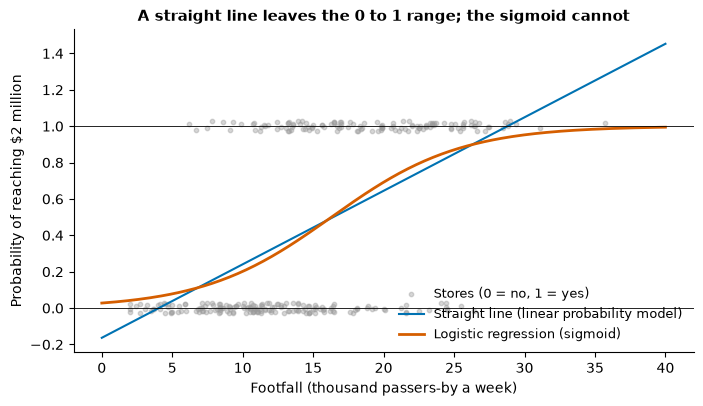

Straight line at footfall 2:  -0.08
Straight line at footfall 38: 1.37


In [21]:
stores["hit_target"] = (stores["sales"] >= 2000).astype(int)
print(f"Share of stores at or above $2 million: {stores['hit_target'].mean():.0%}")

X_f = stores[["footfall"]]
lpm = LinearRegression().fit(X_f, stores["hit_target"])
logit = LogisticRegression().fit(X_f, stores["hit_target"])

grid = pd.DataFrame({"footfall": np.linspace(0, 40, 200)})
fig, ax = plt.subplots()
jitter = np.random.default_rng(8).uniform(-0.03, 0.03, len(stores))
ax.scatter(stores["footfall"], stores["hit_target"] + jitter, s=10, alpha=0.4, color=GREY, label="Stores (0 = no, 1 = yes)")
ax.plot(grid["footfall"], lpm.predict(grid), color=BLUE, label="Straight line (linear probability model)")
ax.plot(grid["footfall"], logit.predict_proba(grid)[:, 1], color=ORANGE, lw=2, label="Logistic regression (sigmoid)")
ax.axhline(0, color="black", lw=0.6)
ax.axhline(1, color="black", lw=0.6)
ax.set_xlabel("Footfall (thousand passers-by a week)")
ax.set_ylabel("Probability of reaching $2 million")
ax.set_title("A straight line leaves the 0 to 1 range; the sigmoid cannot")
ax.legend(frameon=False, fontsize=9, loc="lower right")
plt.show()

print(f"Straight line at footfall 2:  {lpm.predict(pd.DataFrame({'footfall': [2]}))[0]:.2f}")
print(f"Straight line at footfall 38: {lpm.predict(pd.DataFrame({'footfall': [38]}))[0]:.2f}")

The straight line gives impossible "probabilities" at both ends; the S-shaped sigmoid stays between 0 and 1 and is steepest in the middle, where a store's fate is most uncertain.

**Log loss** for one store is −log(p) if the store did hit the target, and −log(1 − p) if it did not:

| Model's probability for a store that **did** hit the target | Log loss | Squared error (1 − p)² |
|---|---|---|
| 0.9 (confident, right) | 0.11 | 0.01 |
| 0.5 (unsure) | 0.69 | 0.25 |
| 0.1 (confident, wrong) | 2.30 | 0.81 |
| 0.01 (very confident, wrong) | 4.61 | 0.98 |

Squared error can never exceed 1, but log loss grows without limit as a wrong prediction becomes more confident. That is why logistic regression produces cautious probabilities.

**Choosing a threshold is a business decision.** For predictive maintenance, missing a failure (a false negative) may cost a production line; an unneeded inspection (a false positive) costs an hour of an engineer's time. A low threshold, flagging any machine above, say, 0.2, can be right. For fraud, blocking an honest customer's card has a cost too. Gordon's point is that the costs of false alarms and missed events should shape the model and its validation.

> **Check your understanding.** Why is a logistic coefficient **not** "the change in probability per unit of x"? (Hint: look at how steep the orange curve is at footfall 5 and at footfall 20.)

---

## Part 14: Business case: choosing new store sites (core discussion, extension detail)

Corner & Co. has four candidate sites and budget for two. The property team has measured each one. You are asked for a **prediction** of annual sales, with honest uncertainty, and a recommendation.

We refit the log model on **all 300 stores** (the model was chosen on training data and checked once on test data, Part 5's rule 4) and ask statsmodels for a **95% prediction interval**: a range that should contain the actual sales of about 95 in 100 stores like this one. It is much wider than the confidence interval of the average, because it includes each store's own noise.

In [22]:
final = smf.ols(log_formula, data=stores).fit()
sites = pd.DataFrame({
    "site": ["A: High Street", "B: Ring Road", "C: Village", "D: Station Mall"],
    "region": ["Downtown", "Suburb", "Rural", "Downtown"],
    "floor_area": [2800, 4800, 2200, 9000],
    "footfall": [26.0, 15.0, 6.0, 30.0],
    "competitor_miles": [0.2, 1.5, 4.0, 0.1],
    "parking": [0, 1, 1, 0],
})
pi = final.get_prediction(sites).summary_frame(alpha=0.05)
sites["predicted"] = np.exp(pi["mean"]).round(0)
sites["95% PI low"] = np.exp(pi["obs_ci_lower"]).round(0)
sites["95% PI high"] = np.exp(pi["obs_ci_upper"]).round(0)

ranges = {c: (stores[c].min(), stores[c].max()) for c in ["floor_area", "footfall", "competitor_miles"]}
sites["outside data range"] = sites.apply(
    lambda r: ", ".join(c for c, (lo, hi) in ranges.items() if not lo <= r[c] <= hi) or "-", axis=1)
print("Predicted annual sales, thousand US dollars")
print(sites.drop(columns=["region", "parking"]).to_string(index=False))

Predicted annual sales, thousand US dollars
           site  floor_area  footfall  competitor_miles  predicted  95% PI low  95% PI high outside data range
 A: High Street        2800      26.0               0.2     2168.0      1725.0       2725.0                  -
   B: Ring Road        4800      15.0               1.5     2587.0      2059.0       3251.0                  -
     C: Village        2200       6.0               4.0     1057.0       841.0       1330.0                  -
D: Station Mall        9000      30.0               0.1     5570.0      4407.0       7039.0         floor_area


Discussion questions (groups of three, 10 minutes):

1. Which two sites would you recommend on the predictions alone? Now look at the intervals and the range check: does your choice change?
2. Site D's prediction is the highest. What does the "outside data range" column say about it, and what would you ask the property team before trusting it?
3. The model predicts **sales**, but the decision is about **profit**. What else would you need (rent, staff, fit-out cost)? Which of those could a second regression predict?
4. Which coefficient would head office be tempted to read causally ("let's add a car park to site A"), and why is that not what this model supports?
5. Write the recommendation in four parts, as on Day 3: **finding, evidence, action with an owner, and how you would know it worked** (for example, compare actual first-year sales with the interval).

A good answer separates the **prediction** (what the model says, with its interval and its range) from the **judgement** (what the business should do, including what the model cannot see).

---

## Part 15: Practice, quiz and summary

### Practice

#### Core

**Core 1.** Fit `sales ~ footfall` on the training stores. Write the slope as a business sentence with units, a sensible step size and the words "on average".

**Core 2.** Add `C(region, Treatment('Rural'))` to the dollar model. Write one sentence for each region coefficient, naming the reference category.

**Core 3.** For the model in Core 2, compute test R², RMSE and MAE, and compare them with the baseline "predict the training mean". Write two sentences a manager could understand.

**Core 4.** Draw the residual plot of `sales ~ floor_area` (one predictor, in dollars). Describe the pattern you see in one sentence, using the words "funnel" or "curve".

#### Stretch

**Stretch 1.** Using the `vif_table` function, compute VIFs for a model with `floor_area` and `staff` only. Then replace them with a single column, `staff_per_1000_sqft = staff / floor_area * 1000`. What happens to the VIFs, and what does the new coefficient mean?

**Stretch 2.** Re-run Part 5 with `random_state` = 2, 3, 4 and 5. How much do the test R² and RMSE move? What does that tell you about quoting a test score to three decimals?

**Stretch 3.** Fit the log model with and without `promo`. Does adding the promotion improve the test RMSE? Is "it does not improve prediction" the same as "it has no effect"?

#### Challenge

**Challenge 1.** Use the `diamonds` data in `data/diamonds.csv`. Predict `price` from `carat` in dollars and in logs (log price on log carat), with an 80/20 split. Draw both residual plots, compare test errors in dollars, and write the log model's slope as an elasticity. (Lab 1 explored diamonds descriptively; this is a different, predictive question.)

**Challenge 2.** Write a function `report(model_formula, train, test)` that fits a statsmodels formula on `train` and prints test R², RMSE, MAE (back-transforming if the formula starts with `np.log(`), the coefficients with 95% intervals, and the VIFs.

**Challenge 3.** In Part 13, add `np.log(floor_area)` to the logistic model. Choose a threshold so that at most 10% of stores flagged "will reach $2 million" actually fall short, and explain why a property team might want such a rule.

### Quiz

1. Give one business question that calls for a **predictive** regression and one that calls for an **explanatory** one. What would you check differently?
2. Write the slope 0.031 in `log(sales) ~ … + footfall` as a business sentence.
3. A model of salary includes `gender` with "Female" as the reference. The `Male` coefficient is 2,500. What exactly does that number compare?
4. Why can't we include a dummy for every region **and** an intercept?
5. Why is test-set R² a fairer measure of a predictive model than training R²?
6. A model's RMSE is $120 thousand and its MAE is $60 thousand. What does the gap suggest?
7. What does adjusted R² do that R² does not?
8. Sketch a residual plot showing heteroscedasticity. What does it mean for a manager reading "accurate to within $X"?
9. Two predictors have VIFs of 12. Is the model useless? Answer for prediction and for explanation.
10. Training RMSE falls and test RMSE rises as you add predictors. What is happening, and what do you do?
11. Name one danger of extrapolation, with an example from your own field.
12. Why does a straight-line model fail for a yes/no outcome, and what does the sigmoid do about it?

### Summary

| Idea | Remember |
|---|---|
| Purpose | Decide first: **predict** (judge test error) or **explain** (judge coefficients, confounding) |
| Coefficient | "On average, among cases like these, one [step] more of x goes with [b × step, units] more y, **holding the others constant**" |
| Dummies | One 0/1 column per category except the **reference**; coefficients are differences from it |
| Train/test | Split first, fit on training, test **once**; random split for cross-sectional data, time order for time series |
| R² / adj R² | Share of variation accounted for; adjusted R² penalises useless predictors; neither is "accuracy" |
| RMSE / MAE | Typical error in the target's units; RMSE ≥ MAE; compare with a baseline and the scale |
| Residual plots | Want a flat, even band; **curve** = wrong shape, **funnel** = unequal error sizes |
| Logs | Turn multiplicative effects into additive ones; read coefficients as percentages or elasticities |
| VIF | 1 ÷ (1 − R²_j); > 5 flags overlap; ruins coefficients, rarely predictions |
| Overfitting | Training error always falls with flexibility; test error tells the truth |
| Extrapolation | Report the data range; models that agree inside it can disagree wildly outside |
| Causation | A coefficient is a comparison, not an intervention; confounders bias it; experiments settle it |
| Logistic | Probability via the sigmoid; fitted by log loss; threshold set by error costs |

**References:** Gordon, M. E. (2023). *Business analytics: Combining data, analysis and judgement to inform decisions* (Chapter 8). SAGE. Google (n.d.). *Machine learning crash course: Logistic regression*. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An introduction to statistical learning* (2nd ed., Chapters 3 and 4). Springer. Wooldridge, J. M. (2020). *Introductory econometrics: A modern approach* (7th ed., Chapters 3 and 6). Cengage.

**Next:** [Text as a feature](D4_lecture_text_features.md) in period 4, with the Assignment 2 briefing, and the [Assignment 2 guide](guides/assignment2_predictive_report.md). Tomorrow, Lab 5 applies Parts 5–9 to a different data set.

---

## For the facilitator

This notebook covers **periods P1–P3** of Day 4 (Monday, theory only). The text-features lecture and the Assignment 2 briefing follow in P4. No Assignment 2 or Lab 5 answers are given: the lecture uses synthetic store data, never the house-price generator or the fuel-economy data, and the Challenge using diamonds asks a predictive question that Lab 1 did not.

| Period | Minutes | Content | Notes |
|---|---|---|---|
| P1 | 5 | Setup; the data table; Part 1 prediction vs explanation | Ask students for one prediction and one explanation question from their own jobs |
| P1 | 15 | Part 2: simple regression, the coefficient sentence | Take guesses for the "per 100 sq ft" prediction; have pairs fix the colleague's sentence |
| P1 | 15 | Part 3: multiple regression, holding constant, the coefficient table | Insist on units and the clause in every sentence |
| P1 | 10 | Part 4: dummies, reference category, the Downtown surprise | Show of hands on the Downtown prediction before running |
| P2 | 12 | Part 5: train/test | Link back to Day 3's time-ordered split |
| P2 | 15 | Part 6: the four measures, baseline, noise columns | Students compute one measure by hand on paper for three residuals |
| P2 | 18 | Part 7: three simulated patterns, then the store model | Students sketch the bottom row before running |
| P3 | 8 | Part 8: log model (core idea); skip the comparison cell if short of time | Read the elasticity sentence aloud |
| P3 | 12 | Part 9: VIF and the bootstrap table | Ask: "Would you let head office read the checkouts coefficient?" |
| P3 | 8 | Part 10: overfitting chart (cross-validation is an extension) | Collect the degree predictions first |
| P3 | 5 | Part 11: the superstore | One-sentence takeaway: report the range |
| P3 | 7 | Part 12: the promotion; Part 14 discussion questions 1–2 if time | If short of time, set Part 14 as homework |
| Later | 20 | Part 13: logistic regression (extension) | Fits the Day 7 review, the online week, or faster students |
| Self-study | — | Part 15: practice and quiz | Core items first; Challenge 1 is good preparation for Lab 5 |

If P1 overruns, shorten Part 4 to the "changing the reference does not change predictions" cell. If students struggle with logs, teach only the percentage reading in Part 8 and leave the table for self-study. If the group finishes Part 12 early, start the text-features lecture's Part 1 in the last minutes of P3.